# Prueba del modelo de perros y gatos

En este cuaderno pongo a prueba los modelos del laboratorio *Clasificación de Imágenes con Redes Neuronales Convolucionales* que nos pasó el profesor. No cambio su lógica: copio sus celdas tal como están (mismas capas, misma preparación de las imágenes, mismas épocas) y solo agrego mediciones alrededor.

Lo que hago aquí:

1. Vuelvo a entrenar los 8 modelos del cuaderno y registro sus capas, sus pérdidas y cuánto tarda cada uno en entrenar y en clasificar.
2. Guardo el modelo que el profesor eligió guardar (`modeloCNN_AD`), lo cargo de nuevo y reviso que responda igual.
3. Lo uso para clasificar 100 imágenes que no están en el dataset (50 perros y 50 gatos sacadas de Wikimedia Commons).
4. Mido qué tan bien acierta y cuántos recursos gasta: memoria, procesador, GPU y tiempos de respuesta.

Las celdas copiadas del profesor están marcadas con **[Profesor]**. Las que agregué yo están marcadas con **[Medición]**.

## 0. Preparación

**[Medición]** Cargo las librerías, reviso si hay GPU y dejo listas unas funciones pequeñas para medir tiempo y memoria. Activo el crecimiento gradual de memoria en la GPU para que TensorFlow no la reserve toda de una vez y así poder medir cuánto usa de verdad.

In [1]:
import os, time, json, platform, glob, zipfile
import numpy as np
import pandas as pd
import psutil
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf

for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

import sys
EN_COLAB = 'google.colab' in sys.modules
os.makedirs('resultados', exist_ok=True)
os.makedirs('modelos', exist_ok=True)

PROCESO = psutil.Process(os.getpid())
HAY_GPU = len(tf.config.list_physical_devices('GPU')) > 0

def ram_mb():
    return PROCESO.memory_info().rss / 1024**2

def gpu_mb(clave='current'):
    if not HAY_GPU:
        return float('nan')
    return tf.config.experimental.get_memory_info('GPU:0')[clave] / 1024**2

class TiempoPorEpoca(tf.keras.callbacks.Callback):
    """Guarda cuántos segundos tarda cada época. No cambia el entrenamiento."""
    def on_train_begin(self, logs=None):
        self.tiempos = []
    def on_epoch_begin(self, epoch, logs=None):
        self._inicio = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        self.tiempos.append(time.perf_counter() - self._inicio)

# Aquí se va guardando lo que se mide de cada modelo
registro = {}

print('TensorFlow:', tf.__version__)
print('Python:', platform.python_version())
print('GPU:', tf.config.list_physical_devices('GPU'))
if HAY_GPU:
    print('Detalle GPU:', tf.config.experimental.get_device_details(tf.config.list_physical_devices('GPU')[0]))
print('Núcleos de CPU:', psutil.cpu_count(logical=True))
print('RAM total (GB):', round(psutil.virtual_memory().total / 1024**3, 1))
print('Entorno Colab:', EN_COLAB)

2026-11-15 15:40:12.653412: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.20.0
Python: 3.11.13
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Detalle GPU: {'compute_capability': (8, 9), 'device_name': 'NVIDIA GeForce RTX 4070 Laptop GPU'}
Núcleos de CPU: 16
RAM total (GB): 11.5
Entorno Colab: False


## 1. Cuaderno del profesor

### 1.1 Comparación CPU y GPU

**[Profesor]** Celda original que multiplica dos matrices de 12.000 × 12.000 en CPU y en GPU.

In [2]:
import time

# Print available devices
print("CPUs:", tf.config.list_physical_devices('CPU'))
print("GPUs:", tf.config.list_physical_devices('GPU'))

# Size of the matrices (bigger = easier to see difference)
N = 12000

# Create random matrices
a = tf.random.uniform((N, N))
b = tf.random.uniform((N, N))

# ------------------------------
# CPU TEST
# ------------------------------
with tf.device('/CPU:0'):
    start = time.time()
    c_cpu = tf.matmul(a, b)
    # Force TensorFlow to finish the operation
    _ = c_cpu.numpy()
    cpu_time = time.time() - start

print(f"CPU time: {cpu_time:.4f} seconds")

# ------------------------------
# GPU TEST
# ------------------------------
try:
    with tf.device('/GPU:0'):
        start = time.time()
        c_gpu = tf.matmul(a, b)
        _ = c_gpu.numpy()
        gpu_time = time.time() - start
    print(f"GPU time: {gpu_time:.4f} seconds")

except Exception as e:
    print("GPU not available or error using GPU.")

CPUs: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


I0000 00:00:1794757217.249312      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5518 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9
2026-11-15 15:40:17.407138: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 576000000 exceeds 10% of free system memory.


2026-11-15 15:40:18.324019: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 576000000 exceeds 10% of free system memory.


2026-11-15 15:40:24.666511: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 576000000 exceeds 10% of free system memory.


CPU time: 16.1913 seconds


2026-11-15 15:40:34.252597: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 576000000 exceeds 10% of free system memory.


GPU time: 15.1552 seconds


In [3]:
# [Medición] Relación entre los dos tiempos y liberación de las matrices
if 'gpu_time' in globals():
    print(f"La GPU fue {cpu_time / gpu_time:.1f} veces más rápida que la CPU")
registro_hw = {'cpu_matmul_s': cpu_time, 'gpu_matmul_s': globals().get('gpu_time', float('nan'))}
del a, b, c_cpu
if 'c_gpu' in globals():
    del c_gpu

La GPU fue 1.1 veces más rápida que la CPU


**Lo que observé:** la CPU tardó 16,19 s y la GPU 15,16 s, casi lo mismo. Esto no es la velocidad real de la GPU. La celda no hace una llamada de calentamiento antes de medir, así que el tiempo de la GPU incluye su arranque y la copia del resultado (una matriz de 576 MB) de vuelta a la memoria normal.

### 1.2 Dataset cats_vs_dogs

**[Profesor]** Descarga del dataset y vista de algunas imágenes.

In [4]:
import tensorflow_datasets as tfds

#Download data set Dogs and Cats
ds_data, ds_info = tfds.load(
    'cats_vs_dogs',
    as_supervised=True,
    with_info=True)

In [5]:
print(ds_info.splits['train'].num_examples)

23262


2026-11-15 15:40:50.038293: I tensorflow/core/kernels/data/tf_record_dataset_op.cc:396] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608
2026-11-15 15:40:50.236335: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


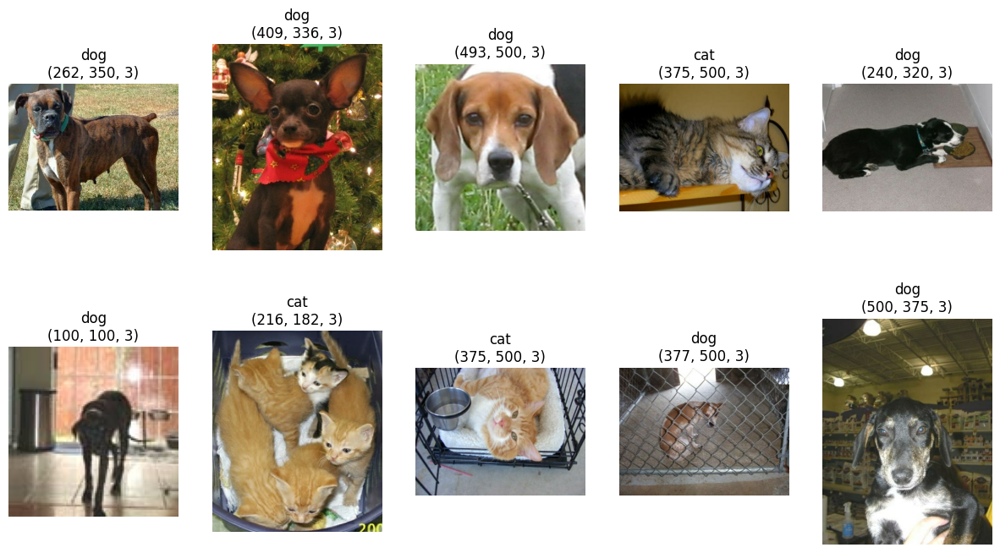

In [6]:
import matplotlib.pyplot as plt

class_names = ds_info.features['label'].names

plt.figure(figsize=(15,8))

train_ds = ds_data['train']

for i, (image, label) in enumerate(train_ds.take(10)):
    # Mostrar imagen
    plt.subplot(2,5,i+1)
    plt.imshow(image)
    # Título con clase y dimensiones
    plt.title(
        f"{class_names[label.numpy()]}\n{image.shape}"
    )
    plt.axis('off')
plt.show()

*Nota:* en la celda original había un primer ciclo que dibujaba las 10 imágenes en el mismo recuadro y luego el segundo ciclo las sobrescribía. Dejé solo el segundo porque es el que se ve en la gráfica; el resultado visual es el mismo.

### 1.3 Preparación de las imágenes

**[Profesor]** Redimensiona a 100 × 100 y divide entre 255.

In [7]:
IMG_SIZE = 100

def preprocess(image, label):

    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = image / 255.0

    return image, label

train_ds_norm = train_ds.map(preprocess)

In [8]:
# [Medición] Guardo una referencia a esta primera función porque más adelante el
# cuaderno define otra con el mismo nombre. La necesito para preparar las 100 fotos igual.
preprocess_paso1 = preprocess

In [9]:
BATCH_SIZE = 32

train_ds_batch = train_ds_norm.batch(BATCH_SIZE)

In [10]:
for images, labels in train_ds_batch.take(1):

    print("Forma batch imágenes:")
    print(images.shape)

Forma batch imágenes:
(32, 100, 100, 3)


2026-11-15 15:40:51.498655: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


### 1.4 Modelo 1 — `modelo_denso` (red densa a color)

**[Profesor]** Aplana la imagen de 100 × 100 × 3 y la pasa por una capa de 128 neuronas. Se entrena 5 épocas sin validación.

In [11]:
tf.keras.backend.clear_session()

modelo_denso = tf.keras.Sequential([

    tf.keras.layers.Flatten(input_shape=(100,100,3)),

    tf.keras.layers.Dense(128, activation='relu'),

    tf.keras.layers.Dense(1, activation='sigmoid')
])

modelo_denso.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
modelo_denso.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 30000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,840,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,840,257 (14.65 MB)

 Trainable params: 3,840,257 (14.65 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
t_modelo_denso = TiempoPorEpoca()   # [Medición]

history = modelo_denso.fit(
    train_ds_batch,
    epochs=5,
    callbacks=[t_modelo_denso]      # [Medición] solo toma el tiempo
)
registro['modelo_denso'] = dict(modelo=modelo_denso, historia=history.history,
                                tiempos=t_modelo_denso.tiempos, entrada='RGB 100x100x3',
                                lote=32, epocas=5, validacion='Sin validación')

Epoch 1/5


2026-11-15 15:40:53.876493: I external/local_xla/xla/service/service.cc:163] XLA service 0x7519d4006390 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-11-15 15:40:53.876565: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 4070 Laptop GPU, Compute Capability 8.9
2026-11-15 15:40:53.985276: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


2026-11-15 15:40:54.491183: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 90300


2026-11-15 15:40:54.980365: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


2026-11-15 15:40:55.982798: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_310', 16 bytes spill stores, 16 bytes spill loads



2026-11-15 15:40:56.259338: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_310', 272 bytes spill stores, 272 bytes spill loads



... (532 outputs left out)

706/727 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6324 - loss: 0.6414

713/727 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6323 - loss: 0.6414

720/727 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6323 - loss: 0.6415

727/727 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6272 - loss: 0.6453


### 1.5 Modelo 2 — `modelo_cnn` (CNN a color)

**[Profesor]** Dos capas de convolución con sus reducciones (pooling), y luego la parte densa. También 5 épocas sin validación.

In [13]:
tf.keras.backend.clear_session()

modelo_cnn = tf.keras.Sequential([

    tf.keras.layers.Conv2D(
        32,
        (3,3),
        activation='relu',
        input_shape=(100,100,3)
    ),

    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(
        64,
        (3,3),
        activation='relu'
    ),

    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),

    tf.keras.layers.Dense(1, activation='sigmoid')
])
modelo_cnn.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 33856)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,333,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,353,217 (16.61 MB)

 Trainable params: 4,353,217 (16.61 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
modelo_cnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [15]:
t_modelo_cnn = TiempoPorEpoca()   # [Medición]

history_cnn = modelo_cnn.fit(
    train_ds_batch,
    epochs=5,
    callbacks=[t_modelo_cnn]       # [Medición]
)
registro['modelo_cnn'] = dict(modelo=modelo_cnn, historia=history_cnn.history,
                              tiempos=t_modelo_cnn.tiempos, entrada='RGB 100x100x3',
                              lote=32, epocas=5, validacion='Sin validación')

Epoch 1/5


2026-11-15 15:41:32.925112: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


2026-11-15 15:41:33.874703: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_574', 16 bytes spill stores, 16 bytes spill loads



2026-11-15 15:41:34.375847: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_574', 272 bytes spill stores, 272 bytes spill loads



  1/727 ━━━━━━━━━━━━━━━━━━━━ 1:47:46 9s/step - accuracy: 0.4688 - loss: 0.7072

  5/727 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.5220 - loss: 1.0869  

... (756 outputs left out)

717/727 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9239 - loss: 0.1921

722/727 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9239 - loss: 0.1920

727/727 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9240 - loss: 0.1919

727/727 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9304 - loss: 0.1761


### 1.6 Modelos 3, 4 y 5 — `modeloDenso`, `modeloCNN` y `modeloCNN2` (escala de grises)

**[Profesor]** Tres modelos que reciben la imagen en escala de grises (100 × 100 × 1):

- `modeloDenso`: dos capas densas de 150 neuronas.
- `modeloCNN`: tres convoluciones (32, 64 y 128 filtros) con pooling, y una capa densa de 100.
- `modeloCNN2`: igual a `modeloCNN` pero con *Dropout* de 0.5 antes de aplanar.

In [16]:
#Crear los modelos iniciales
#Usan sigmoid como salida (en lugar de softmax) para mostrar como podria funcionar con dicha funcion de activacion.
#Sigmoid regresa siempre datos entre 0 y 1. Realizamos el entrenamiento para al final considerar que si la respuesta se
#acerca a 0, es un gato, y si se acerca a 1, es un perro.

IMAGE_SZ=100

modeloDenso = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(IMAGE_SZ, IMAGE_SZ, 1)),
  tf.keras.layers.Dense(150, activation='relu'),
  tf.keras.layers.Dense(150, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

modeloCNN = tf.keras.models.Sequential([
  # Extracción inicial de características
  tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(IMAGE_SZ, IMAGE_SZ, 1)),
   # Reducción dimensional
  tf.keras.layers.MaxPooling2D(2, 2),
   # Extracción de patrones más complejos
  tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),
   # Características de mayor nivel
  tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),
  # Conversión a vector
  tf.keras.layers.Flatten(),
   # Clasificación
  tf.keras.layers.Dense(IMAGE_SZ, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

modeloCNN2 = tf.keras.models.Sequential([
  tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(IMAGE_SZ, IMAGE_SZ, 1)),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),

  # Regularización
  tf.keras.layers.Dropout(0.5),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(IMAGE_SZ, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

In [17]:
modeloDenso.summary()
modeloCNN.summary()
modeloCNN2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 10000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 150)            │     1,500,150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 150)            │        22,650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           151 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,522,951 (5.81 MB)

 Trainable params: 1,522,951 (5.81 MB)

 Non-trainable params: 0 (0.00 B)

Model: "sequential_2"

... (5 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 98, 98, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 21, 21, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 100)            │     1,280,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,372,873 (5.24 MB)

 Trainable params: 1,372,873 (5.24 MB)

 Non-trainable params: 0 (0.00 B)

**[Profesor]** Segunda preparación: pasa a escala de grises, redimensiona y divide entre 255. Ojo: se aplica sobre `train_ds_norm`, que ya venía dividido entre 255 en el paso 1.3. Esto lo reviso más adelante en la sección 4.

In [18]:
IMG_SIZE = 100

# Preprocesamiento optimizado
def preprocess(image, label):
    image = tf.image.rgb_to_grayscale(image)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

# Aplicar transformaciones
train_ds_processed = (
    train_ds_norm
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .cache()
    .prefetch(tf.data.AUTOTUNE)
)

# Convertir dataset a arreglos numpy
X = np.concatenate([
    image.numpy()[np.newaxis, ...]
    for image, label in train_ds_processed
])

y = np.array([
    label.numpy()
    for image, label in train_ds_processed
])

print("Shape X:", X.shape)
print("Shape y:", y.shape)

Shape X: (23262, 100, 100, 1)
Shape y: (23262,)


2026-11-15 15:42:45.610436: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [19]:
# [Medición] Rango real de los píxeles que reciben los modelos en escala de grises
print(f"Mínimo: {X.min():.6f} | Máximo: {X.max():.6f} | Promedio: {X.mean():.6f}")
print(f"Perros (1): {int(y.sum())} | Gatos (0): {int((y == 0).sum())}")
registro_datos = {'x_min': float(X.min()), 'x_max': float(X.max()), 'x_mean': float(X.mean()),
                  'n_total': int(len(y)), 'n_perros': int(y.sum()), 'n_gatos': int((y == 0).sum())}

Mínimo: 0.000000 | Máximo: 0.003921 | Promedio: 0.001792
Perros (1): 11604 | Gatos (0): 11658


In [20]:
#Compilar modelos. Usar crossentropy binario ya que tenemos solo 2 opciones (perro o gato)
modeloDenso.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

modeloCNN.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

modeloCNN2.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

In [21]:
from tensorflow.keras.callbacks import TensorBoard
#La variable de tensorboard se envia en el arreglo de "callbacks" (hay otros tipos de callbacks soportados)
#En este caso guarda datos en la carpeta indicada en cada epoca, de manera que despues
#Tensorboard los lee para hacer graficas
tensorboardDenso = TensorBoard(log_dir='logs/denso')

In [22]:
t_modeloDenso = TiempoPorEpoca()   # [Medición]

h_modeloDenso = modeloDenso.fit(X, y, batch_size=32,
                validation_split=0.15,
                epochs=10,
                callbacks=[tensorboardDenso, t_modeloDenso])
registro['modeloDenso'] = dict(modelo=modeloDenso, historia=h_modeloDenso.history,
                               tiempos=t_modeloDenso.tiempos, entrada='Gris 100x100x1',
                               lote=32, epocas=10, validacion='validation_split=0.15')

2026-11-15 15:42:49.569435: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 790880000 exceeds 10% of free system memory.


Epoch 1/10


2026-11-15 15:42:54.395040: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-11-15 15:42:54.395148: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-11-15 15:42:54.395182: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-11-15 15:42:54.395201: I external/l

2026-11-15 15:42:55.844052: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_128', 36 bytes spill stores, 36 bytes spill loads

2026-11-15 15:42:56.028729: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_128', 136 bytes spill stores, 164 bytes spill loads



2026-11-15 15:42:56.182367: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_351', 4 bytes spill stores, 4 bytes spill loads

2026-11-15 15:42:56.355850: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_128', 8 bytes spill stores, 8 bytes spill loads



2026-11-15 15:42:56.602396: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_365', 16 bytes spill stores, 16 bytes spill loads



... (871 outputs left out)

600/618 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6301 - loss: 0.6364

607/618 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6301 - loss: 0.6364

613/618 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6302 - loss: 0.6364

618/618 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6343 - loss: 0.6362 - val_accuracy: 0.6206 - val_loss: 0.6464


*Nota:* el cuaderno original abre TensorBoard en este punto (`%tensorboard --logdir logs`). Aquí no lo abro porque el cuaderno corre sin pantalla, pero los registros sí quedan guardados en la carpeta `logs/` y las curvas de pérdida las dibujo en la sección 2.

In [23]:
tensorboardCNN = TensorBoard(log_dir='logs/cnn')
t_modeloCNN = TiempoPorEpoca()   # [Medición]
h_modeloCNN = modeloCNN.fit(X, y, batch_size=128,
                validation_split=0.15,
                epochs=20,
                callbacks=[tensorboardCNN, t_modeloCNN])
registro['modeloCNN'] = dict(modelo=modeloCNN, historia=h_modeloCNN.history,
                             tiempos=t_modeloCNN.tiempos, entrada='Gris 100x100x1',
                             lote=128, epocas=20, validacion='validation_split=0.15')

Epoch 1/20


  1/155 ━━━━━━━━━━━━━━━━━━━━ 16:28 6s/step - accuracy: 0.4609 - loss: 0.6932

  3/155 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.4657 - loss: 0.6933 

  5/155 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.4679 - loss: 0.6934

  7/155 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.4706 - loss: 0.6934

  9/155 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.4741 - loss: 0.6934

... (1,576 outputs left out)

149/155 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5085 - loss: 0.6931

151/155 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5085 - loss: 0.6931

153/155 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5084 - loss: 0.6931

155/155 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.5029 - loss: 0.6932 - val_accuracy: 0.4914 - val_loss: 0.6932


In [24]:
tensorboardCNN2 = TensorBoard(log_dir='logs/cnn2')
t_modeloCNN2 = TiempoPorEpoca()   # [Medición]
h_modeloCNN2 = modeloCNN2.fit(X, y, batch_size=128,
                validation_split=0.15,
                epochs=20,
                callbacks=[tensorboardCNN2, t_modeloCNN2])
registro['modeloCNN2'] = dict(modelo=modeloCNN2, historia=h_modeloCNN2.history,
                              tiempos=t_modeloCNN2.tiempos, entrada='Gris 100x100x1',
                              lote=128, epocas=20, validacion='validation_split=0.15')

Epoch 1/20


  1/155 ━━━━━━━━━━━━━━━━━━━━ 11:19 4s/step - accuracy: 0.4531 - loss: 0.6932

  3/155 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.4735 - loss: 0.6932 

  5/155 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.4847 - loss: 0.6931

  7/155 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.4903 - loss: 0.6932

  9/155 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.4909 - loss: 0.6934

... (1,573 outputs left out)

149/155 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.5018 - loss: 0.6931

151/155 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.5018 - loss: 0.6931

153/155 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.5018 - loss: 0.6931

155/155 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.5029 - loss: 0.6931 - val_accuracy: 0.4914 - val_loss: 0.6933


### 1.7 Modelos 6, 7 y 8 — con aumento de datos (`_AD`)

**[Profesor]** Los mismos tres modelos, pero entrenados con imágenes que se giran, desplazan, inclinan, acercan y voltean al azar en cada época. Se entrenan 50 épocas con 19.700 imágenes y se validan con las 3.562 restantes.

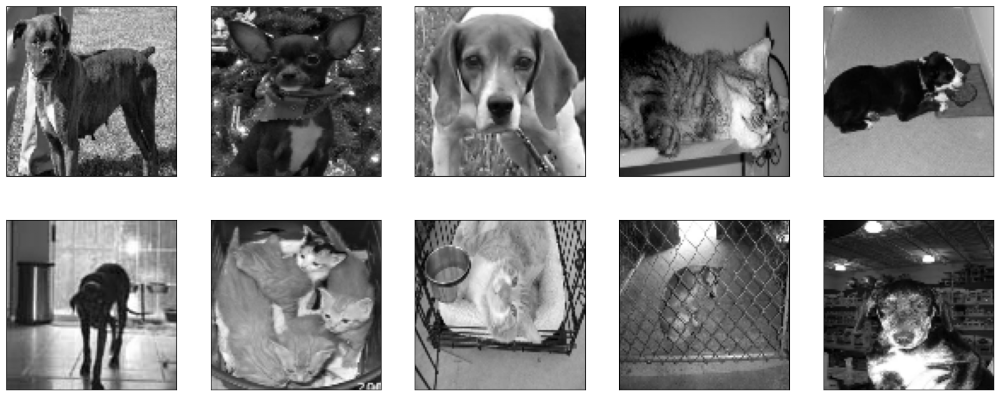

In [25]:
#ver las imagenes de la variable X sin modificaciones por aumento de datos
plt.figure(figsize=(20, 8))
for i in range(10):
  plt.subplot(2, 5, i+1)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(X[i].reshape(IMAGE_SZ, IMAGE_SZ), cmap="gray")

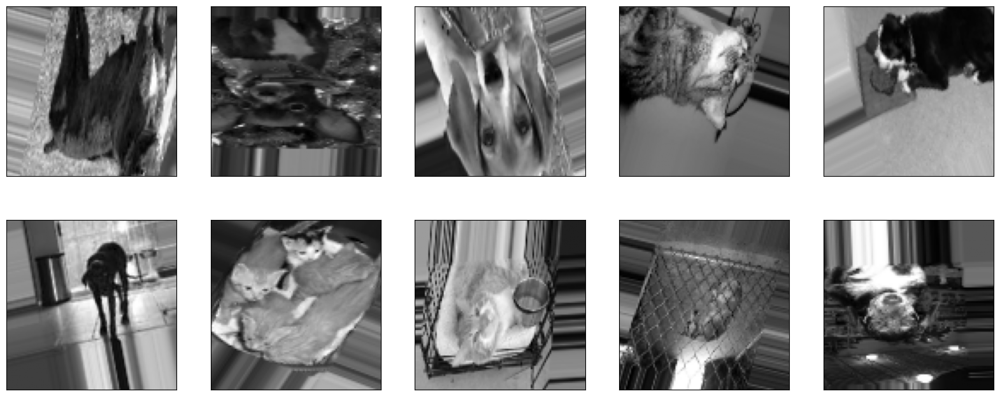

In [26]:
#Realizar el aumento de datos con varias transformaciones. Al final, graficar 10 como ejemplo
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=15,
    zoom_range=[0.7, 1.4],
    horizontal_flip=True,
    vertical_flip=True
)

datagen.fit(X)

plt.figure(figsize=(20,8))

for imagen, etiqueta in datagen.flow(X, y, batch_size=10, shuffle=False):
  for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(imagen[i].reshape(IMAGE_SZ, IMAGE_SZ), cmap="gray")
  break

In [27]:
modeloDenso_AD = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(IMAGE_SZ, IMAGE_SZ, 1)),
  tf.keras.layers.Dense(150, activation='relu'),
  tf.keras.layers.Dense(150, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

modeloCNN_AD = tf.keras.models.Sequential([
  tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(IMAGE_SZ, IMAGE_SZ, 1)),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),

  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(100, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

modeloCNN2_AD = tf.keras.models.Sequential([
  tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(IMAGE_SZ, IMAGE_SZ, 1)),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),

  tf.keras.layers.Dropout(0.5),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(250, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

In [28]:
modeloDenso_AD.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

modeloCNN_AD.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

modeloCNN2_AD.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

# [Medición] El cuaderno original no imprime el resumen de estos tres modelos
modeloDenso_AD.summary()
modeloCNN_AD.summary()
modeloCNN2_AD.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 10000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 150)            │     1,500,150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 150)            │        22,650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           151 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,522,951 (5.81 MB)

 Trainable params: 1,522,951 (5.81 MB)

 Non-trainable params: 0 (0.00 B)

Model: "sequential_5"

... (5 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_11 (Conv2D)              │ (None, 98, 98, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 21, 21, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 250)            │     3,200,250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │           251 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,293,173 (12.56 MB)

 Trainable params: 3,293,173 (12.56 MB)

 Non-trainable params: 0 (0.00 B)

In [29]:
#Separar los datos de entrenamiento y los datos de pruebas en variables diferentes

len(X) * .85 #19700
len(X) - 19700 #3562

X_entrenamiento = X[:19700]
X_validacion = X[19700:]

y_entrenamiento = y[:19700]
y_validacion = y[19700:]

In [30]:
#Usar la funcion flow del generador para crear un iterador que podamos enviar como entrenamiento a la funcion FIT del modelo
data_gen_entrenamiento = datagen.flow(X_entrenamiento, y_entrenamiento, batch_size=32)
tensorboardDenso_AD = TensorBoard(log_dir='logs/denso_AD')
t_modeloDenso_AD = TiempoPorEpoca()   # [Medición]

h_modeloDenso_AD = modeloDenso_AD.fit(
    data_gen_entrenamiento,
    epochs=50, batch_size=32,
    validation_data=(X_validacion, y_validacion),
    steps_per_epoch=int(np.ceil(len(X_entrenamiento) / float(32))),
    validation_steps=int(np.ceil(len(X_validacion) / float(32))),
    callbacks=[tensorboardDenso_AD, t_modeloDenso_AD]
)
registro['modeloDenso_AD'] = dict(modelo=modeloDenso_AD, historia=h_modeloDenso_AD.history,
                                  tiempos=t_modeloDenso_AD.tiempos, entrada='Gris 100x100x1 + aumento',
                                  lote=32, epocas=50, validacion='19.700 / 3.562')

Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


  1/616 ━━━━━━━━━━━━━━━━━━━━ 27:50 3s/step - accuracy: 0.4688 - loss: 0.6933

  4/616 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.4818 - loss: 0.6931

  6/616 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - accuracy: 0.4707 - loss: 0.6936

  8/616 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.4671 - loss: 0.6938

... (12,734 outputs left out)

610/616 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5906 - loss: 0.6665

612/616 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5906 - loss: 0.6665

614/616 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5906 - loss: 0.6665

616/616 ━━━━━━━━━━━━━━━━━━━━ 17s 28ms/step - accuracy: 0.5848 - loss: 0.6687 - val_accuracy: 0.6005 - val_loss: 0.6609


In [31]:
tensorboardCNN_AD = TensorBoard(log_dir='logs-new/cnn_AD')
t_modeloCNN_AD = TiempoPorEpoca()   # [Medición]

h_modeloCNN_AD = modeloCNN_AD.fit(
    data_gen_entrenamiento,
    epochs=50, batch_size=32,
    validation_data=(X_validacion, y_validacion),
    steps_per_epoch=int(np.ceil(len(X_entrenamiento) / float(32))),
    validation_steps=int(np.ceil(len(X_validacion) / float(32))),
    callbacks=[tensorboardCNN_AD, t_modeloCNN_AD]
)
registro['modeloCNN_AD'] = dict(modelo=modeloCNN_AD, historia=h_modeloCNN_AD.history,
                                tiempos=t_modeloCNN_AD.tiempos, entrada='Gris 100x100x1 + aumento',
                                lote=32, epocas=50, validacion='19.700 / 3.562')

Epoch 1/50


2026-11-15 16:01:42.108123: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


2026-11-15 16:01:42.477804: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_563', 4 bytes spill stores, 4 bytes spill loads



2026-11-15 16:01:43.050189: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_695', 68 bytes spill stores, 68 bytes spill loads



  1/616 ━━━━━━━━━━━━━━━━━━━━ 48:05 5s/step - accuracy: 0.6875 - loss: 0.6931

  4/616 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.6270 - loss: 0.6922

... (11,424 outputs left out)

611/616 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5057 - loss: 0.6931

614/616 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5056 - loss: 0.6931

616/616 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5056 - loss: 0.6931

616/616 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.5028 - loss: 0.6932 - val_accuracy: 0.4921 - val_loss: 0.6932


In [32]:
tensorboardCNN2_AD = TensorBoard(log_dir='logs/cnn2_AD')
t_modeloCNN2_AD = TiempoPorEpoca()   # [Medición]

h_modeloCNN2_AD = modeloCNN2_AD.fit(
    data_gen_entrenamiento,
    epochs=50, batch_size=32,
    validation_data=(X_validacion, y_validacion),
    steps_per_epoch=int(np.ceil(len(X_entrenamiento) / float(32))),
    validation_steps=int(np.ceil(len(X_validacion) / float(32))),
    callbacks=[tensorboardCNN2_AD, t_modeloCNN2_AD]
)
registro['modeloCNN2_AD'] = dict(modelo=modeloCNN2_AD, historia=h_modeloCNN2_AD.history,
                                 tiempos=t_modeloCNN2_AD.tiempos, entrada='Gris 100x100x1 + aumento',
                                 lote=32, epocas=50, validacion='19.700 / 3.562')

Epoch 1/50


2026-11-15 16:14:35.396654: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


2026-11-15 16:14:36.451515: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1093', 200 bytes spill stores, 200 bytes spill loads



  1/616 ━━━━━━━━━━━━━━━━━━━━ 51:17 5s/step - accuracy: 0.6250 - loss: 0.6931

  2/616 ━━━━━━━━━━━━━━━━━━━━ 1:37 158ms/step - accuracy: 0.6016 - loss: 0.6929

  5/616 ━━━━━━━━━━━━━━━━━━━━ 34s 56ms/step - accuracy: 0.5740 - loss: 0.6933  

... (11,670 outputs left out)

611/616 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5022 - loss: 0.6931

613/616 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5022 - loss: 0.6931

616/616 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5022 - loss: 0.6931

616/616 ━━━━━━━━━━━━━━━━━━━━ 16s 27ms/step - accuracy: 0.5014 - loss: 0.6932 - val_accuracy: 0.4921 - val_loss: 0.6932


## 2. Informe de los modelos

**[Medición]** A partir de aquí no entreno nada nuevo: solo organizo lo que salió de la sección 1.

### 2.1 Capas de cada modelo

In [33]:
def tabla_capas(modelo):
    filas = []
    for capa in modelo.layers:
        try:
            forma = tuple(capa.output.shape)
        except Exception:
            forma = '-'
        filas.append({'Capa': capa.name, 'Tipo': capa.__class__.__name__,
                      'Forma de salida': str(forma), 'Parámetros': capa.count_params()})
    return pd.DataFrame(filas)

capas_todas = []
for nombre, r in registro.items():
    t = tabla_capas(r['modelo'])
    t.insert(0, 'Modelo', nombre)
    capas_todas.append(t)
    print(f"\n=== {nombre} ({r['entrada']}) ===")
    print(t.drop(columns='Modelo').to_string(index=False))
    print(f"Total de parámetros: {r['modelo'].count_params():,}")
pd.concat(capas_todas).to_csv('resultados/capas_modelos.csv', index=False)


=== modelo_denso (RGB 100x100x3) ===
   Capa    Tipo Forma de salida  Parámetros
flatten Flatten   (None, 30000)           0
  dense   Dense     (None, 128)     3840128
dense_1   Dense       (None, 1)         129
Total de parámetros: 3,840,257

=== modelo_cnn (RGB 100x100x3) ===
           Capa         Tipo    Forma de salida  Parámetros
         conv2d       Conv2D (None, 98, 98, 32)         896
  max_pooling2d MaxPooling2D (None, 49, 49, 32)           0
       conv2d_1       Conv2D (None, 47, 47, 64)       18496
max_pooling2d_1 MaxPooling2D (None, 23, 23, 64)           0
        flatten      Flatten      (None, 33856)           0
          dense        Dense        (None, 128)     4333696
        dense_1        Dense          (None, 1)         129
Total de parámetros: 4,353,217

=== modeloDenso (Gris 100x100x1) ===
     Capa    Tipo Forma de salida  Parámetros
flatten_1 Flatten   (None, 10000)           0
  dense_2   Dense     (None, 150)     1500150
  dense_3   Dense     (None, 150

### 2.2 Pérdidas y exactitud durante el entrenamiento

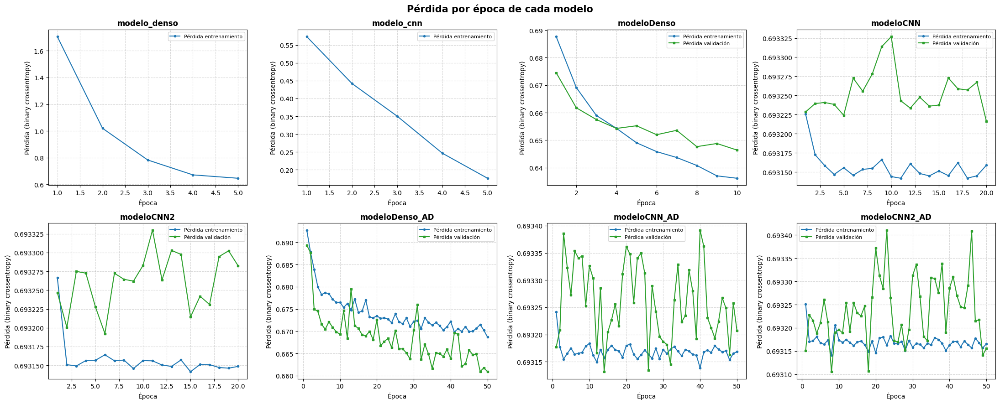

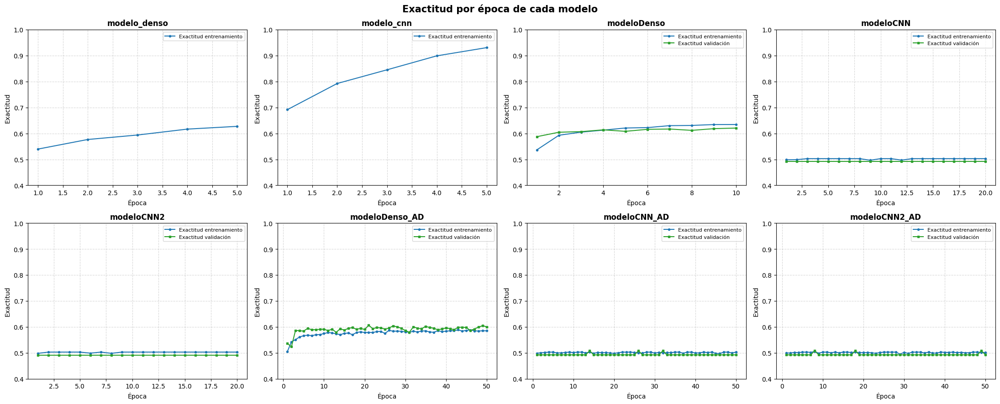

In [34]:
fig, ejes = plt.subplots(2, 4, figsize=(22, 9))
for eje, (nombre, r) in zip(ejes.flat, registro.items()):
    h = r['historia']
    epocas = range(1, len(h['loss']) + 1)
    eje.plot(epocas, h['loss'], 'o-', color='tab:blue', label='Pérdida entrenamiento', markersize=3)
    if 'val_loss' in h:
        eje.plot(epocas, h['val_loss'], 's-', color='tab:green', label='Pérdida validación', markersize=3)
    eje.set_title(nombre, fontweight='bold')
    eje.set_xlabel('Época')
    eje.set_ylabel('Pérdida (binary crossentropy)')
    eje.grid(True, linestyle='--', alpha=0.5)
    eje.legend(fontsize=8)
fig.suptitle('Pérdida por época de cada modelo', fontsize=15, fontweight='bold')
fig.tight_layout()
plt.savefig('resultados/curvas_perdida.png', dpi=130, bbox_inches='tight')
plt.show()

fig, ejes = plt.subplots(2, 4, figsize=(22, 9))
for eje, (nombre, r) in zip(ejes.flat, registro.items()):
    h = r['historia']
    epocas = range(1, len(h['accuracy']) + 1)
    eje.plot(epocas, h['accuracy'], 'o-', color='tab:blue', label='Exactitud entrenamiento', markersize=3)
    if 'val_accuracy' in h:
        eje.plot(epocas, h['val_accuracy'], 's-', color='tab:green', label='Exactitud validación', markersize=3)
    eje.set_title(nombre, fontweight='bold')
    eje.set_xlabel('Época')
    eje.set_ylabel('Exactitud')
    eje.set_ylim(0.4, 1.0)
    eje.grid(True, linestyle='--', alpha=0.5)
    eje.legend(fontsize=8)
fig.suptitle('Exactitud por época de cada modelo', fontsize=15, fontweight='bold')
fig.tight_layout()
plt.savefig('resultados/curvas_exactitud.png', dpi=130, bbox_inches='tight')
plt.show()

historias = []
for nombre, r in registro.items():
    df = pd.DataFrame(r['historia'])
    df.insert(0, 'epoca', range(1, len(df) + 1))
    df.insert(0, 'modelo', nombre)
    df['segundos'] = r['tiempos']
    historias.append(df)
pd.concat(historias).to_csv('resultados/historial_entrenamiento.csv', index=False)

### 2.3 Tiempo de clasificación de cada modelo

Mido cuánto tarda cada modelo en responder con una sola imagen y con un lote de 32. Antes de medir hago 5 llamadas de calentamiento, porque la primera llamada siempre es más lenta mientras TensorFlow prepara todo. Cada medida es el promedio de 50 repeticiones.

In [35]:
muestra_rgb = next(iter(train_ds_batch))[0]                  # 32 imágenes RGB ya preparadas
muestra_gris = tf.convert_to_tensor(X_validacion[:32])      # 32 imágenes en gris

def medir_clasificacion(modelo, lote, repeticiones=50):
    una = lote[:1]
    for _ in range(5):                       # calentamiento
        modelo(una, training=False); modelo(lote, training=False)
    t = []
    for _ in range(repeticiones):
        inicio = time.perf_counter(); _ = modelo(una, training=False).numpy(); t.append(time.perf_counter() - inicio)
    t_lote = []
    for _ in range(repeticiones):
        inicio = time.perf_counter(); _ = modelo(lote, training=False).numpy(); t_lote.append(time.perf_counter() - inicio)
    return np.mean(t) * 1000, np.mean(t_lote) * 1000

for nombre, r in registro.items():
    lote = muestra_rgb if r['entrada'].startswith('RGB') else muestra_gris
    ms_1, ms_32 = medir_clasificacion(r['modelo'], lote)
    r['ms_imagen'] = ms_1
    r['ms_lote32'] = ms_32
    print(f"{nombre:16s}  1 imagen: {ms_1:7.2f} ms  |  lote de 32: {ms_32:7.2f} ms  ({ms_32/32:.3f} ms por imagen)")

modelo_denso      1 imagen:    4.21 ms  |  lote de 32:    4.61 ms  (0.144 ms por imagen)


modelo_cnn        1 imagen:    8.47 ms  |  lote de 32:    7.57 ms  (0.237 ms por imagen)


modeloDenso       1 imagen:    8.76 ms  |  lote de 32:   11.85 ms  (0.370 ms por imagen)


modeloCNN         1 imagen:   18.46 ms  |  lote de 32:   16.47 ms  (0.515 ms por imagen)


modeloCNN2        1 imagen:   10.32 ms  |  lote de 32:   10.88 ms  (0.340 ms por imagen)


modeloDenso_AD    1 imagen:    4.29 ms  |  lote de 32:    4.09 ms  (0.128 ms por imagen)


modeloCNN_AD      1 imagen:    9.40 ms  |  lote de 32:    9.49 ms  (0.297 ms por imagen)


modeloCNN2_AD     1 imagen:    9.48 ms  |  lote de 32:   11.73 ms  (0.366 ms por imagen)


### 2.4 Comparación general

In [36]:
filas = []
for nombre, r in registro.items():
    h = r['historia']
    params = r['modelo'].count_params()
    filas.append({
        'Modelo': nombre,
        'Entrada': r['entrada'],
        'Parámetros': params,
        'Tamaño (MB)': round(params * 4 / 1024**2, 2),
        'Épocas': len(h['loss']),
        'Lote': r['lote'],
        'Validación': r['validacion'],
        'Pérdida inicial': round(h['loss'][0], 4),
        'Pérdida final': round(h['loss'][-1], 4),
        'Exactitud final (entren.)': round(h['accuracy'][-1], 4),
        'Pérdida val. final': round(h['val_loss'][-1], 4) if 'val_loss' in h else None,
        'Exactitud val. final': round(h['val_accuracy'][-1], 4) if 'val_accuracy' in h else None,
        'Mejor exactitud val.': round(max(h['val_accuracy']), 4) if 'val_accuracy' in h else None,
        'Tiempo total (s)': round(sum(r['tiempos']), 1),
        'Segundos por época': round(np.mean(r['tiempos']), 2),
        'Clasificar 1 imagen (ms)': round(r['ms_imagen'], 2),
        'Clasificar 32 imágenes (ms)': round(r['ms_lote32'], 2),
    })
comparacion = pd.DataFrame(filas).set_index('Modelo')
comparacion.to_csv('resultados/resultados_entrenamiento.csv')
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)
comparacion

,Entrada,Parámetros,Tamaño (MB),Épocas,Lote,Validación,Pérdida inicial,Pérdida final,Exactitud final (entren.),Pérdida val. final,Exactitud val. final,Mejor exactitud val.,Tiempo total (s),Segundos por época,Clasificar 1 imagen (ms),Clasificar 32 imágenes (ms)
Modelo,,,,,,,,,,,,,,,,
modelo_denso,RGB 100x100x3,3840257,14.65,5,32,Sin validación,1.7061,0.6453,0.6272,NaN,NaN,NaN,37.0,7.40,4.21,4.61
modelo_cnn,RGB 100x100x3,4353217,16.61,5,32,Sin validación,0.5736,0.1761,0.9304,NaN,NaN,NaN,54.0,10.81,8.47,7.57
modeloDenso,Gris 100x100x1,1522951,5.81,10,32,validation_split=0.15,0.6876,0.6362,0.6343,0.6464,0.6206,0.6206,62.9,6.29,8.76,11.85
modeloCNN,Gris 100x100x1,1372873,5.24,20,128,validation_split=0.15,0.6932,0.6932,0.5029,0.6932,0.4914,0.4914,112.0,5.60,18.46,16.47
modeloCNN2,Gris 100x100x1,1372873,5.24,20,128,validation_split=0.15,0.6933,0.6931,0.5029,0.6933,0.4914,0.4914,109.5,5.47,10.32,10.88
modeloDenso_AD,Gris 100x100x1 + aumento,1522951,5.81,50,32,19.700 / 3.562,0.6928,0.6687,0.5848,0.6609,0.6005,0.6061,824.9,16.50,4.29,4.09
modeloCNN_AD,Gris 100x100x1 + aumento,1372873,5.24,50,32,19.700 / 3.562,0.6932,0.6932,0.5028,0.6932,0.4921,0.5079,770.1,15.40,9.40,9.49
modeloCNN2_AD,Gris 100x100x1 + aumento,3293173,12.56,50,32,19.700 / 3.562,0.6933,0.6932,0.5014,0.6932,0.4921,0.5079,779.4,15.59,9.48,11.73


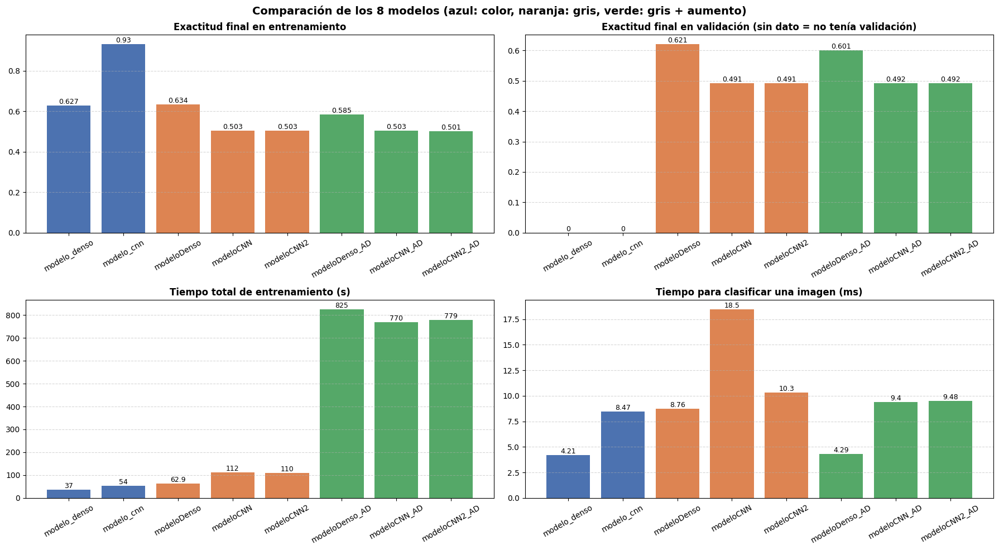

In [37]:
nombres = list(comparacion.index)
colores = ['#4C72B0', '#4C72B0', '#DD8452', '#DD8452', '#DD8452', '#55A868', '#55A868', '#55A868']
fig, ejes = plt.subplots(2, 2, figsize=(18, 10))
datos = [
    ('Exactitud final (entren.)', 'Exactitud final en entrenamiento'),
    ('Exactitud val. final', 'Exactitud final en validación (sin dato = no tenía validación)'),
    ('Tiempo total (s)', 'Tiempo total de entrenamiento (s)'),
    ('Clasificar 1 imagen (ms)', 'Tiempo para clasificar una imagen (ms)'),
]
for eje, (col, titulo) in zip(ejes.flat, datos):
    valores = comparacion[col].fillna(0).values
    barras = eje.bar(nombres, valores, color=colores)
    eje.bar_label(barras, fmt='%.3g', fontsize=9)
    eje.set_title(titulo, fontweight='bold')
    eje.tick_params(axis='x', rotation=30)
    eje.grid(True, axis='y', linestyle='--', alpha=0.5)
fig.suptitle('Comparación de los 8 modelos (azul: color, naranja: gris, verde: gris + aumento)', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.savefig('resultados/comparacion_modelos.png', dpi=130, bbox_inches='tight')
plt.show()

### Lo que observé en el entrenamiento

Estos son los resultados de mi ejecución (Docker, TensorFlow 2.20, RTX 4070 Laptop):

| Modelo | Entrada | Pérdida final | Exactitud entren. | Exactitud val. | Tiempo total |
|---|---|---|---|---|---|
| modelo_denso | Color | 0,6453 | 0,6272 | — | 37 s |
| modelo_cnn | Color | 0,1761 | 0,9304 | — | 54 s |
| modeloDenso | Gris | 0,6362 | 0,6343 | 0,6206 | 63 s |
| modeloCNN | Gris | 0,6932 | 0,5029 | 0,4914 | 112 s |
| modeloCNN2 | Gris | 0,6931 | 0,5029 | 0,4914 | 110 s |
| modeloDenso_AD | Gris + aumento | 0,6687 | 0,5848 | 0,6005 | 825 s |
| modeloCNN_AD | Gris + aumento | 0,6932 | 0,5028 | 0,4921 | 770 s |
| modeloCNN2_AD | Gris + aumento | 0,6932 | 0,5014 | 0,4921 | 779 s |

- **Solo aprendieron 4 de los 8 modelos:** `modelo_denso`, `modelo_cnn`, `modeloDenso` y `modeloDenso_AD`. La mejor fue la CNN a color, con 93 % en entrenamiento. No tiene validación, así que no se sabe cuánto de eso es memoria. Entre los que sí tienen validación, el mejor fue `modeloDenso`, con 62 %.
- **Las cuatro CNN en escala de grises no aprendieron nada.** Su pérdida se queda en 0,6931–0,6934 de principio a fin. Ese es justo el valor de un modelo que siempre responde 0,5, y en validación quedan en 49 %, que es lo mismo que adivinar.
- **La causa es la doble división entre 255.** La celda de escala de grises vuelve a dividir entre 255 imágenes que ya venían divididas (sección 1.3). Los píxeles que reciben estos modelos van de 0 a 0,0039, cuando deberían ir de 0 a 1 (lo medí en la sección 1.6). Con valores tan pequeños la imagen casi no influye en la respuesta. Las redes densas en gris logran aprender un poco a pesar de esto, pero las CNN no. No corregí el código porque la idea era probar el modelo tal como está.
- **El aumento de datos no ayudó.** Hizo el entrenamiento unas 7 veces más largo (50 épocas contra 10 o 20) y ningún modelo mejoró.
- **Tiempo de clasificación:** todos los modelos clasifican una imagen en 4–18 ms. Una imagen o un lote de 32 tardan casi lo mismo: con modelos tan pequeños el costo está en mandar el trabajo a la GPU, no en el cálculo.
- **Dónde están los parámetros:** casi todos quedan en la primera capa `Dense` después de `Flatten`. En `modeloCNN_AD` esa capa tiene 1.280.100 de los 1.372.873 parámetros (93 %).

## 3. Guardar y cargar el modelo

**[Profesor]** La celda 114 del cuaderno original guarda `modeloCNN_AD` en formato `.h5` y luego lo convierte a TensorFlow.js. Hago el guardado igual. No instalo `tensorflowjs` porque al instalarlo cambia la versión de TensorFlow del entorno y eso dañaría las mediciones; la prueba de este cuaderno es en Python.

Además lo guardo en el formato nuevo de Keras (`.keras`), que es el recomendado en esta versión.

In [38]:
modeloCNN_AD.save('perros-gatos-cnn-ad.h5')

In [39]:
# [Medición] Copia en la carpeta modelos/ y versión .keras
modeloCNN_AD.save('modelos/perros-gatos-cnn-ad.h5')
modeloCNN_AD.save('modelos/perros-gatos-cnn-ad.keras')
for ruta in ['modelos/perros-gatos-cnn-ad.h5', 'modelos/perros-gatos-cnn-ad.keras']:
    print(f"{ruta}: {os.path.getsize(ruta) / 1024**2:.2f} MB")

modelos/perros-gatos-cnn-ad.h5: 15.76 MB
modelos/perros-gatos-cnn-ad.keras: 15.75 MB


Ahora lo cargo como si fuera otro programa que solo tiene el archivo. Mido cuánto tarda en cargar y cuánta memoria ocupa, y reviso que dé exactamente las mismas respuestas que el modelo original con las 3.562 imágenes de validación.

In [40]:
recursos = {}

ram_antes = ram_mb(); gpu_antes = gpu_mb()
inicio = time.perf_counter()
modelo_cargado = tf.keras.models.load_model('modelos/perros-gatos-cnn-ad.h5')
recursos['carga_h5_s'] = time.perf_counter() - inicio
recursos['ram_por_carga_mb'] = ram_mb() - ram_antes
recursos['gpu_por_carga_mb'] = gpu_mb() - gpu_antes

inicio = time.perf_counter()
modelo_cargado_keras = tf.keras.models.load_model('modelos/perros-gatos-cnn-ad.keras')
recursos['carga_keras_s'] = time.perf_counter() - inicio

pred_original = modeloCNN_AD.predict(X_validacion, verbose=0)
pred_h5 = modelo_cargado.predict(X_validacion, verbose=0)
pred_keras = modelo_cargado_keras.predict(X_validacion, verbose=0)

print(f"Tiempo de carga .h5: {recursos['carga_h5_s']:.3f} s | .keras: {recursos['carga_keras_s']:.3f} s")
print(f"RAM que sumó la carga: {recursos['ram_por_carga_mb']:.1f} MB | GPU: {recursos['gpu_por_carga_mb']:.1f} MB")
print("¿El .h5 responde igual que el original?   ", np.allclose(pred_original, pred_h5, atol=1e-6))
print("¿El .keras responde igual que el original?", np.allclose(pred_original, pred_keras, atol=1e-6))
eval_val = modelo_cargado.evaluate(X_validacion, y_validacion, verbose=0)
recursos['val_loss_cargado'], recursos['val_acc_cargado'] = eval_val
print(f"Modelo cargado en validación -> pérdida: {eval_val[0]:.4f} | exactitud: {eval_val[1]:.4f}")
print(f"Predicciones 'perro' en validación: {(pred_h5 >= 0.5).sum()} de {len(pred_h5)}")

/usr/local/lib/python3.11/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 12 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Tiempo de carga .h5: 0.181 s | .keras: 0.362 s
RAM que sumó la carga: 0.5 MB | GPU: 5.2 MB
¿El .h5 responde igual que el original?    True
¿El .keras responde igual que el original? True


Modelo cargado en validación -> pérdida: 0.6932 | exactitud: 0.4921
Predicciones 'perro' en validación: 0 de 3562


### Lo que observé al guardar y cargar

- El modelo se guarda y se carga sin problemas. El `.h5` carga en 0,18 s y el `.keras` en 0,36 s.
- Después de cargarlo responde **exactamente igual** que el original con las 3.562 imágenes de validación (las dos comprobaciones dan `True`).
- El archivo pesa 15,8 MB aunque los pesos ocupan 5,24 MB. Esto pasa porque también guarda el estado del optimizador Adam, que lleva dos valores extra por cada parámetro.
- Cargarlo sumó apenas 0,5 MB de RAM y 5,2 MB de memoria de GPU.
- En validación da 49 % y además nunca responde "perro". Esto ya anticipa lo que pasa con las 100 fotos.

## 4. Prueba con 100 imágenes nuevas

Las 100 fotos están en `imagenes_prueba/` (50 en `perros/` y 50 en `gatos/`). Son fotos de Wikimedia Commons, no vienen del dataset `cats_vs_dogs`; la lista con autor y licencia está en `imagenes_prueba/fuentes.csv`.

Para que la prueba sea justa con el modelo, cada foto pasa exactamente por la misma preparación que vieron las imágenes de entrenamiento:

1. Primera preparación del profesor (`preprocess_paso1`): 100 × 100 y división entre 255.
2. Segunda preparación del profesor (`preprocess`): escala de grises, 100 × 100 y otra vez división entre 255.

Si en Colab no está la carpeta, la celda siguiente descomprime `imagenes_prueba.zip` o pide subirlo.

In [41]:
if not os.path.isdir('imagenes_prueba'):
    if not os.path.exists('imagenes_prueba.zip') and EN_COLAB:
        from google.colab import files
        files.upload()
    with zipfile.ZipFile('imagenes_prueba.zip') as z:
        z.extractall('.')

rutas, etiquetas = [], []
for carpeta, etiqueta in [('gatos', 0), ('perros', 1)]:
    archivos = sorted(glob.glob(f'imagenes_prueba/{carpeta}/*.jpg'))
    rutas += archivos
    etiquetas += [etiqueta] * len(archivos)
etiquetas = np.array(etiquetas)
print(f"Imágenes encontradas: {len(rutas)} | gatos: {(etiquetas == 0).sum()} | perros: {(etiquetas == 1).sum()}")

def preparar(ruta):
    """Lee una foto y le aplica las mismas dos preparaciones del cuaderno del profesor."""
    imagen = tf.io.decode_jpeg(tf.io.read_file(ruta), channels=3)   # uint8 RGB, igual que tfds
    imagen, _ = preprocess_paso1(imagen, 0)                          # celda 1.3
    imagen, _ = preprocess(imagen, 0)                                # celda 1.6
    return imagen

originales = [tf.io.decode_jpeg(tf.io.read_file(r), channels=3).numpy() for r in rutas]

Imágenes encontradas: 100 | gatos: 50 | perros: 50


### 4.1 Latencia, memoria y procesador

Clasifico las 100 fotos de dos formas:

- **Una por una**, como lo haría una aplicación que recibe una foto a la vez. Separo el tiempo de preparar la foto del tiempo que tarda el modelo.
- **Las 100 de una vez** (un solo lote), como un proceso por lotes.

Mientras tanto mido la RAM del proceso, el pico de memoria de la GPU y el uso de CPU.

In [42]:
def prueba_recursos(modelo, dispositivo):
    with tf.device(dispositivo):
        # calentamiento
        for r in rutas[:5]:
            modelo(tf.expand_dims(preparar(r), 0), training=False)
        if HAY_GPU:
            tf.config.experimental.reset_memory_stats('GPU:0')
        psutil.cpu_percent(interval=None); PROCESO.cpu_percent(interval=None)
        ram_inicio = ram_mb(); ram_pico = ram_inicio
        t_prep, t_modelo, probabilidades = [], [], []
        inicio_total = time.perf_counter()
        for r in rutas:
            a = time.perf_counter(); x = tf.expand_dims(preparar(r), 0); _ = x.numpy(); b = time.perf_counter()
            p = float(modelo(x, training=False).numpy()[0, 0]); c = time.perf_counter()
            t_prep.append((b - a) * 1000); t_modelo.append((c - b) * 1000); probabilidades.append(p)
            ram_pico = max(ram_pico, ram_mb())
        total_uno_a_uno = time.perf_counter() - inicio_total
        cpu_proceso = PROCESO.cpu_percent(interval=None) / psutil.cpu_count()
        cpu_sistema = psutil.cpu_percent(interval=None)
        gpu_pico = gpu_mb('peak')

        lote = tf.stack([preparar(r) for r in rutas])
        modelo.predict(lote, verbose=0)  # calentamiento del lote
        t_lote = []
        for _ in range(10):
            a = time.perf_counter(); modelo.predict(lote, verbose=0); t_lote.append(time.perf_counter() - a)

    t_total = np.array(t_prep) + np.array(t_modelo)
    res = {
        'dispositivo': dispositivo,
        'prep_ms_promedio': np.mean(t_prep),
        'modelo_ms_promedio': np.mean(t_modelo),
        'modelo_ms_mediana': np.median(t_modelo),
        'modelo_ms_p95': np.percentile(t_modelo, 95),
        'modelo_ms_max': np.max(t_modelo),
        'total_ms_promedio': np.mean(t_total),
        'total_ms_p95': np.percentile(t_total, 95),
        'uno_a_uno_100_s': total_uno_a_uno,
        'imagenes_por_segundo_uno_a_uno': len(rutas) / total_uno_a_uno,
        'lote100_ms': np.mean(t_lote) * 1000,
        'imagenes_por_segundo_lote': len(rutas) / np.mean(t_lote),
        'ram_inicio_mb': ram_inicio,
        'ram_pico_mb': ram_pico,
        'gpu_pico_mb': gpu_pico if dispositivo.startswith('/GPU') else float('nan'),
        'cpu_proceso_pct': cpu_proceso,
        'cpu_sistema_pct': cpu_sistema,
    }
    return res, np.array(probabilidades), t_modelo

resultados_disp = []
dispositivos = ['/GPU:0', '/CPU:0'] if HAY_GPU else ['/CPU:0']
probs_por_disp = {}
for d in dispositivos:
    if d == '/CPU:0':
        with tf.device('/CPU:0'):
            modelo_prueba = tf.keras.models.load_model('modelos/perros-gatos-cnn-ad.h5')
    else:
        modelo_prueba = modelo_cargado
    res, probs, lat = prueba_recursos(modelo_prueba, d)
    resultados_disp.append(res)
    probs_por_disp[d] = (probs, lat)

recursos_df = pd.DataFrame(resultados_disp).set_index('dispositivo').T.round(3)
recursos_df

2026-11-15 16:29:18.319963: I external/local_xla/xla/service/service.cc:163] XLA service 0x7519cfd96010 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
2026-11-15 16:29:18.320046: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): Host, Default Version


dispositivo,/GPU:0,/CPU:0
prep_ms_promedio,12.624,7.920
modelo_ms_promedio,10.649,11.799
modelo_ms_mediana,9.894,11.437
modelo_ms_p95,14.119,13.956
modelo_ms_max,22.080,20.347
total_ms_promedio,23.273,19.720
total_ms_p95,31.350,23.234
uno_a_uno_100_s,2.338,1.983
imagenes_por_segundo_uno_a_uno,42.767,50.435
lote100_ms,134.133,188.685


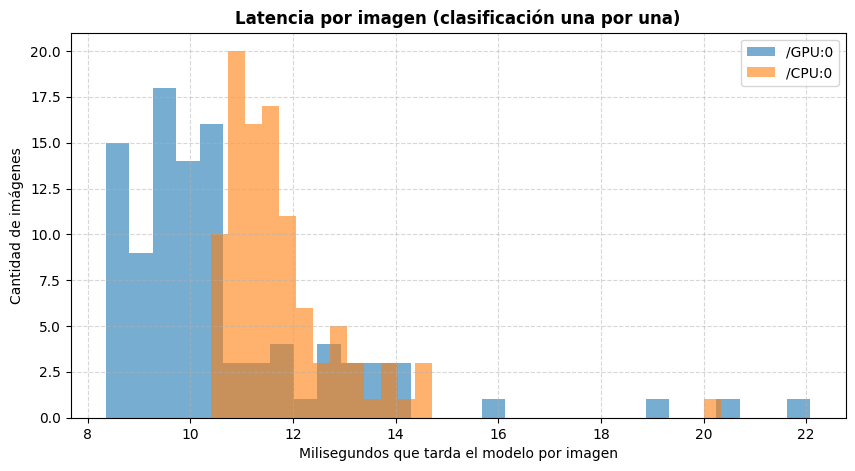

In [43]:
recursos_df.to_csv('resultados/recursos_inferencia.csv')
info_extra = {
    **recursos, **registro_hw, **registro_datos,
    'tamano_h5_mb': os.path.getsize('modelos/perros-gatos-cnn-ad.h5') / 1024**2,
    'tamano_keras_mb': os.path.getsize('modelos/perros-gatos-cnn-ad.keras') / 1024**2,
    'parametros_modeloCNN_AD': modeloCNN_AD.count_params(),
    'tensorflow': tf.__version__,
    'gpu': str(tf.config.list_physical_devices('GPU')),
    'cpu_nucleos': psutil.cpu_count(),
    'ram_total_gb': psutil.virtual_memory().total / 1024**3,
}
with open('resultados/info_entorno.json', 'w', encoding='utf-8') as f:
    json.dump(info_extra, f, indent=2, ensure_ascii=False, default=float)

probs_gpu, lat_gpu = probs_por_disp[dispositivos[0]]
plt.figure(figsize=(10, 5))
for d in dispositivos:
    plt.hist(probs_por_disp[d][1], bins=30, alpha=0.6, label=f'{d}')
plt.xlabel('Milisegundos que tarda el modelo por imagen')
plt.ylabel('Cantidad de imágenes')
plt.title('Latencia por imagen (clasificación una por una)', fontweight='bold')
plt.legend(); plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig('resultados/latencia_por_imagen.png', dpi=130, bbox_inches='tight')
plt.show()

### Lo que observé en los recursos

| Medida | GPU | CPU |
|---|---|---|
| Preparar una foto | 12,6 ms | 7,9 ms |
| Modelo, una foto (promedio / mediana / p95) | 10,6 / 9,9 / 14,1 ms | 11,8 / 11,4 / 14,0 ms |
| Total por foto | 23,3 ms | 19,7 ms |
| 100 fotos una por una | 2,34 s (43 fotos/s) | 1,98 s (50 fotos/s) |
| 100 fotos en un solo lote | 134 ms (746 fotos/s) | 189 ms (530 fotos/s) |
| Uso de CPU del proceso | 5,0 % | 7,9 % |
| Memoria de GPU (pico) | 307 MB | — |

- **Latencia:** una foto suelta tarda unos 20–23 ms en total, y casi la mitad es prepararla, no clasificarla.
- **CPU contra GPU:** con una sola foto la GPU no ayuda; la CPU fue incluso un poco más rápida, porque mandar una imagen tan pequeña a la GPU cuesta más que el cálculo. Con el lote de 100, la GPU fue 1,4 veces más rápida.
- **Memoria:** el modelo es liviano. El proceso ocupaba unos 6,7 GB de RAM, pero casi todo son los datos de entrenamiento que el cuaderno guarda en memoria (23.262 imágenes, más de 900 MB por copia), no el modelo. El pico de 307 MB de GPU incluye todo lo que el proceso tenía en la GPU, también los otros 7 modelos.
- **Procesador:** clasificar las 100 fotos usó entre 5 y 8 % del procesador.

### 4.2 Precisión con las 100 imágenes

Exactitud: 50.00% (50 de 100 aciertos)
El modelo dijo 'perro' 0 veces y 'gato' 100 veces
Probabilidad mínima: 0.498277 | máxima: 0.498277 | promedio: 0.498277

              precision    recall  f1-score   support

        gato     0.5000    1.0000    0.6667        50
       perro     0.0000    0.0000    0.0000        50

    accuracy                         0.5000       100
   macro avg     0.2500    0.5000    0.3333       100
weighted avg     0.2500    0.5000    0.3333       100



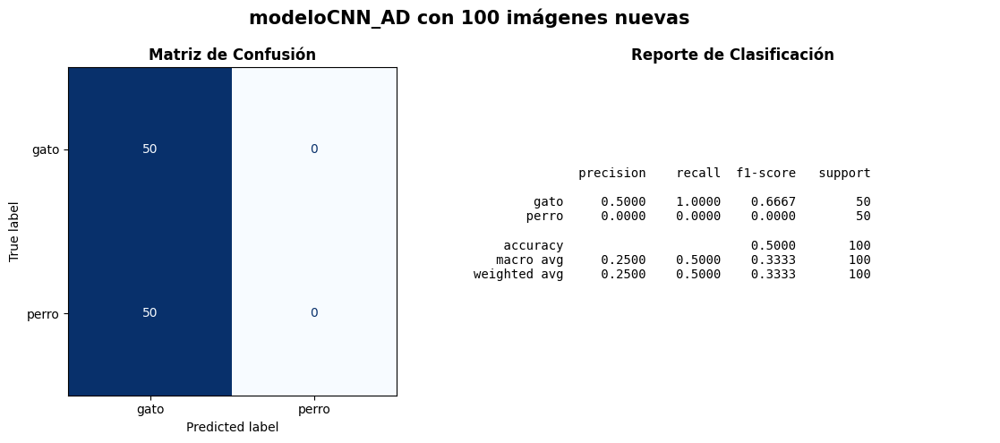

In [44]:
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_fscore_support)

probabilidades = probs_gpu
predicciones = (probabilidades >= 0.5).astype(int)
nombres_clases = ['gato', 'perro']

exactitud = accuracy_score(etiquetas, predicciones)
print(f"Exactitud: {exactitud:.2%} ({(predicciones == etiquetas).sum()} de {len(etiquetas)} aciertos)")
print(f"El modelo dijo 'perro' {predicciones.sum()} veces y 'gato' {(predicciones == 0).sum()} veces")
print(f"Probabilidad mínima: {probabilidades.min():.6f} | máxima: {probabilidades.max():.6f} | promedio: {probabilidades.mean():.6f}")
print()
print(classification_report(etiquetas, predicciones, target_names=nombres_clases, digits=4, zero_division=0))

fig, (ax_cm, ax_rep) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [1, 1.1]})
ConfusionMatrixDisplay.from_predictions(etiquetas, predicciones, display_labels=nombres_clases,
                                        cmap='Blues', colorbar=False, ax=ax_cm)
ax_cm.set_title('Matriz de Confusión', fontsize=12, fontweight='bold')
ax_rep.axis('off')
ax_rep.text(0.0, 0.5, classification_report(etiquetas, predicciones, target_names=nombres_clases, digits=4, zero_division=0),
            fontsize=10, family='monospace', va='center', ha='left')
ax_rep.set_title('Reporte de Clasificación', fontsize=12, fontweight='bold')
fig.suptitle('modeloCNN_AD con 100 imágenes nuevas', fontsize=15, fontweight='bold')
fig.tight_layout()
plt.savefig('resultados/matriz_100_imagenes.png', dpi=130, bbox_inches='tight')
plt.show()

pred_df = pd.DataFrame({
    'archivo': [os.path.basename(r) for r in rutas],
    'real': [nombres_clases[e] for e in etiquetas],
    'prediccion': [nombres_clases[p] for p in predicciones],
    'probabilidad_perro': probabilidades,
    'acierto': predicciones == etiquetas,
    'latencia_modelo_ms': lat_gpu,
})
pred_df.to_csv('resultados/predicciones_100.csv', index=False)
p, r, f, s = precision_recall_fscore_support(etiquetas, predicciones, zero_division=0)
metricas_100 = {'exactitud': exactitud, 'precision_gato': p[0], 'precision_perro': p[1],
                'sensibilidad_gato': r[0], 'sensibilidad_perro': r[1], 'f1_gato': f[0], 'f1_perro': f[1],
                'predichos_perro': int(predicciones.sum())}
with open('resultados/metricas_100.json', 'w', encoding='utf-8') as fjson:
    json.dump(metricas_100, fjson, indent=2, default=float)

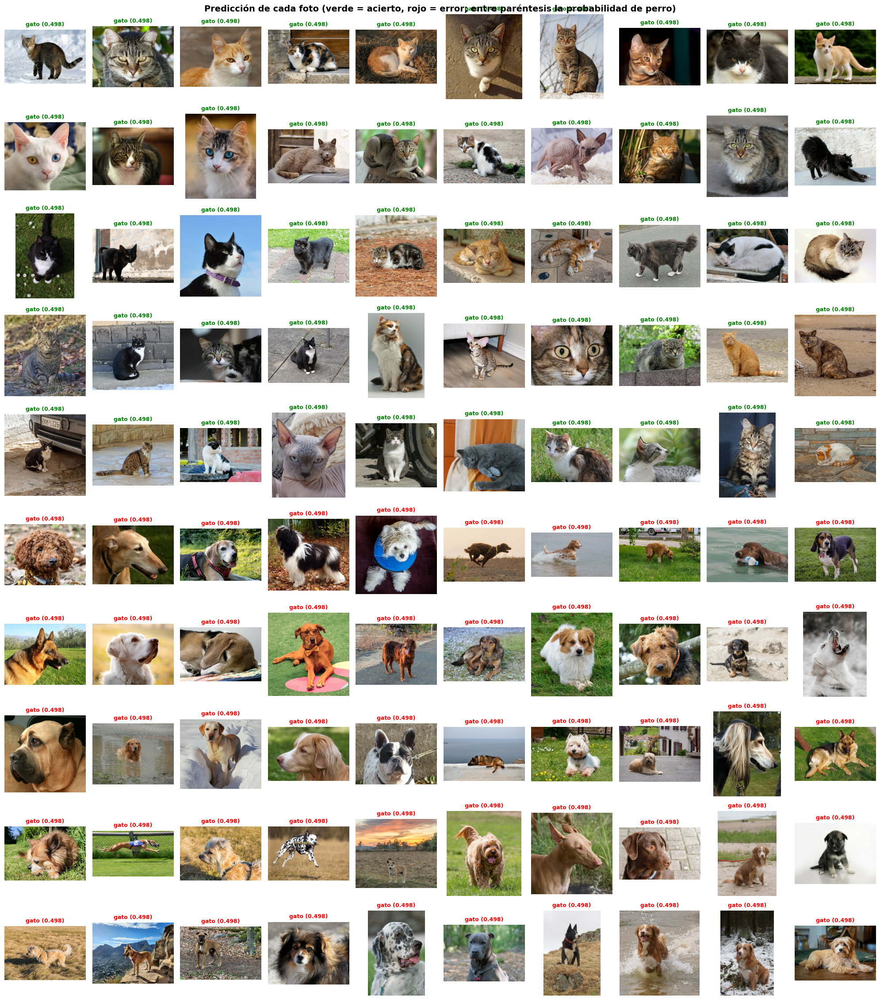

In [45]:
fig, ejes = plt.subplots(10, 10, figsize=(20, 23))
for i, eje in enumerate(ejes.flat):
    eje.imshow(originales[i])
    acierto = predicciones[i] == etiquetas[i]
    eje.set_title(f"{nombres_clases[predicciones[i]]} ({probabilidades[i]:.3f})",
                  color='green' if acierto else 'red', fontsize=9, fontweight='bold')
    eje.axis('off')
fig.suptitle('Predicción de cada foto (verde = acierto, rojo = error; entre paréntesis la probabilidad de perro)',
             fontsize=14, fontweight='bold')
fig.tight_layout()
plt.savefig('resultados/cuadricula_100.png', dpi=90, bbox_inches='tight')
plt.show()

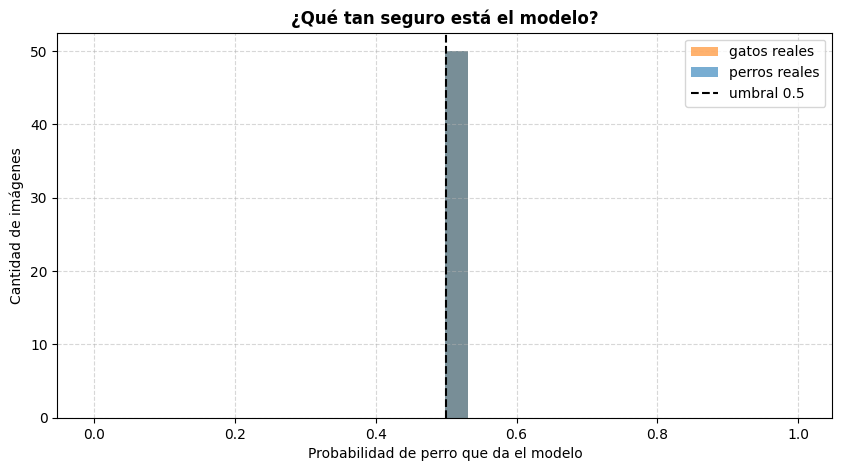

In [46]:
plt.figure(figsize=(10, 5))
plt.hist(probabilidades[etiquetas == 0], bins=30, alpha=0.6, label='gatos reales', color='tab:orange')
plt.hist(probabilidades[etiquetas == 1], bins=30, alpha=0.6, label='perros reales', color='tab:blue')
plt.axvline(0.5, color='black', linestyle='--', label='umbral 0.5')
plt.xlabel('Probabilidad de perro que da el modelo')
plt.ylabel('Cantidad de imágenes')
plt.title('¿Qué tan seguro está el modelo?', fontweight='bold')
plt.legend(); plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig('resultados/confianza_100.png', dpi=130, bbox_inches='tight')
plt.show()

### 4.3 ¿Qué ve el modelo?

Para entender los resultados muestro cómo queda una de las fotos después de las dos preparaciones, y el rango de valores de sus píxeles.

Píxeles después de las dos preparaciones -> mínimo: 0.000000 | máximo: 0.003839


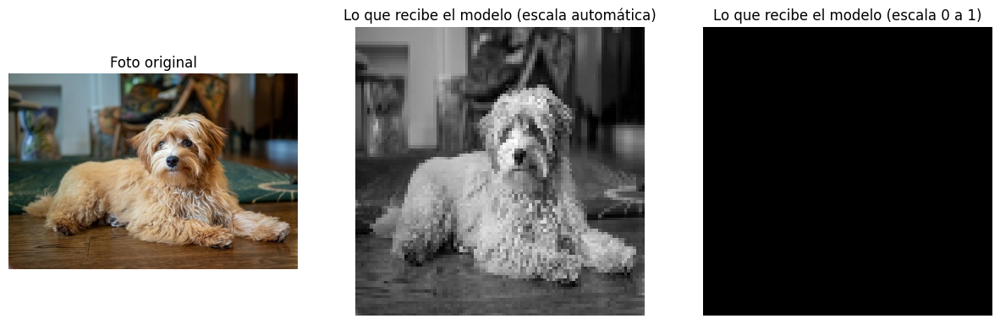

In [47]:
ejemplo = preparar(rutas[-1]).numpy()
print(f"Píxeles después de las dos preparaciones -> mínimo: {ejemplo.min():.6f} | máximo: {ejemplo.max():.6f}")
fig, ejes = plt.subplots(1, 3, figsize=(15, 5))
ejes[0].imshow(originales[-1]); ejes[0].set_title('Foto original')
ejes[1].imshow(ejemplo[:, :, 0], cmap='gray'); ejes[1].set_title('Lo que recibe el modelo (escala automática)')
ejes[2].imshow(ejemplo[:, :, 0], cmap='gray', vmin=0, vmax=1); ejes[2].set_title('Lo que recibe el modelo (escala 0 a 1)')
for e in ejes: e.axis('off')
plt.savefig('resultados/lo_que_ve_el_modelo.png', dpi=110, bbox_inches='tight')
plt.show()

### Lo que observé con las 100 fotos

- **Exactitud: 50 % (50 de 100).** El modelo respondió "gato" en las 100 fotos.
- A todas les dio **la misma probabilidad de ser perro: 0,4983**. Como queda justo debajo del umbral de 0,5, todas salen como gato.
- Acertó los 50 gatos porque siempre dice gato, no porque los reconozca, y falló los 50 perros. Por eso la sensibilidad es 1,00 en gatos y 0,00 en perros.
- Esto no viene de las fotos nuevas: en validación ya tenía 49 % y nunca respondía "perro". La imagen de arriba muestra la causa: lo que recibe el modelo, en su escala real de 0 a 1, es una imagen prácticamente negra.

## 5. Conclusiones

### Qué hice

1. Copié el código del cuaderno del profesor sin cambiar su lógica: mismas capas, misma preparación de las imágenes, mismas épocas, mismo tamaño de lote y misma forma de validar. Solo agregué mediciones alrededor (tiempo por época, tablas de capas, curvas y tiempos de clasificación).
2. Entrené los 8 modelos y los comparé: capas, parámetros, pérdidas, exactitud, tiempo de entrenamiento y tiempo de clasificación.
3. Guardé `modeloCNN_AD`, que es el que guarda la celda del profesor, en `.h5` y en `.keras`. Lo volví a cargar y comprobé que responde igual.
4. Busqué 100 fotos que no están en el dataset: 50 perros y 50 gatos de Wikimedia Commons, revisadas una por una. Las clasifiqué con el modelo cargado, preparándolas exactamente igual que las imágenes de entrenamiento.
5. Medí la precisión con las 100 fotos y los recursos que gasta: memoria RAM y de GPU, uso del procesador y latencias, en GPU y en CPU.

Lo ejecuté en un contenedor Docker con TensorFlow 2.20, la misma versión del Colab del profesor, sobre una GPU RTX 4070 Laptop.

### Conclusiones

- **Como pieza de software, el modelo funciona.** Se guarda y se carga bien, responde igual después de cargarlo, pesa 15,8 MB, carga en menos de medio segundo, clasifica una foto en unos 10 ms y gasta pocos recursos.
- **Como clasificador no sirve en su estado actual.** Con las 100 fotos nuevas acertó el 50 %, lo mismo que lanzar una moneda, porque responde "gato" con la misma probabilidad para cualquier foto.
- **La causa está en la preparación de las imágenes.** En la celda de escala de grises se divide dos veces entre 255. Los píxeles le llegan a las CNN entre 0 y 0,004, y con eso no logran aprender: su pérdida nunca bajó de 0,6932.
- **Entre los 8 modelos, el que mejor aprendió fue `modelo_cnn`**, la CNN a color, que recibe las imágenes bien escaladas: 93 % en entrenamiento. Pero no tiene validación. Entre los que sí tienen validación, el mejor fue `modeloDenso`, con 62 %.
- **El aumento de datos multiplicó el tiempo de entrenamiento por 7 y no mejoró ningún modelo.**
- **Recursos:** con modelos de este tamaño conviene clasificar por lotes. Una foto suelta tarda lo mismo en CPU que en GPU, mientras que en lote la GPU procesa unas 750 fotos por segundo.

Todos los números de este cuaderno quedan guardados en la carpeta `resultados/` (tablas en CSV y JSON, y las gráficas en PNG).

In [48]:
print("Archivos generados:")
for ruta in sorted(glob.glob('resultados/*')) + sorted(glob.glob('modelos/*')):
    print(f"  {ruta}  ({os.path.getsize(ruta) / 1024:.0f} KB)")

Archivos generados:
  resultados/capas_modelos.csv  (3 KB)
  resultados/comparacion_modelos.png  (227 KB)
  resultados/confianza_100.png  (51 KB)
  resultados/cuadricula_100.png  (4483 KB)
  resultados/curvas_exactitud.png  (191 KB)
  resultados/curvas_perdida.png  (521 KB)
  resultados/historial_entrenamiento.csv  (22 KB)
  resultados/info_entorno.json  (1 KB)
  resultados/latencia_por_imagen.png  (64 KB)
  resultados/lo_que_ve_el_modelo.png  (220 KB)
  resultados/matriz_100_imagenes.png  (65 KB)
  resultados/metricas_100.json  (0 KB)
  resultados/predicciones_100.csv  (7 KB)
  resultados/recursos_inferencia.csv  (0 KB)
  resultados/resultados_entrenamiento.csv  (1 KB)
  modelos/perros-gatos-cnn-ad.h5  (16134 KB)
  modelos/perros-gatos-cnn-ad.keras  (16132 KB)
